# App-17 : Vehicle Routing Problem (VRP)

**Navigation** : [<< App-16 Crossword CSP](App-16-Crossword-CSP-Python.ipynb) | [Index](../README.md) | [App-18 Hyperparameter Tuning >>](App-18-HyperparameterTuning-Python.ipynb)

## Objectifs d'apprentissage

Ce carnet est le jumeau **Rust** de [App-17 VRP Python](App-17-VRP-Logistics-Python.ipynb) : il explore le
**Vehicle Routing Problem**, un problème d'optimisation combinatoire qui combine aspects de la recherche et de
la satisfaction de contraintes. La structure suit le jumeau Python ; le moteur de référence change (voir
ci-dessous).

A la fin de ce carnet, vous saurez :
1. Modéliser un VRP comme un problème de recherche (instance, solution, validité)
2. Appliquer des algorithmes de recherche heuristique (insertion gloutonne, 2-opt)
3. Formuler le VRP capacité comme un **programme linéaire en nombres entiers** (MILP flot) et le résoudre à
   l'optimum avec la crate `highs`
4. Comparer honnêtement heuristiques et optimum exact sur la même instance

**Le remodelage assumé** : le jumeau Python termine par le solveur de référence **OR-Tools Routing**
(`pywrapcp`, recherche locale guidée). La carte Rust
([rust-ecosystem-map.md](../../../docs/reference/rust-ecosystem-map.md)) n'a pas d'équivalent Routing :
`ortools` → `highs`, `cp_sat`. Ce carnet formule donc le même VRP comme un **MILP flot** résolu par **HiGHS** —
l'enseignement (un solveur SOTA bat le glouton) est préservé, le moteur change, et la formulation elle-même
devient un objet d'apprentissage.

**Durée estimée** : ~15 min | **Prérequis** : [App-17 VRP Python](App-17-VRP-Logistics-Python.ipynb)


## L'organe : la crate highs

Le jumeau Python construit glouton et 2-opt **à la main**, puis délègue la référence à OR-Tools. En Rust, le
réflexe est le même : les heuristiques restent en **Rust pur** (c'est l'objet du cours), et le solveur de
référence délègue à la crate **`highs`** — bindings sûres au solveur [HiGHS](https://highs.dev), qui **compile
les sources C++ depuis la crate** (cmake + compilateur C++ requis, aucune installation système — contraste
documenté avec `cp_sat`, lot 4 de la même vague, qui exige un solveur installé côté système).

| | Jumeau Python | Ce carnet (Rust) |
|---|---|---|
| Glouton / 2-opt | implémentation manuelle | **Rust pur** (même critère, même geste) |
| Solveur de référence | OR-Tools **Routing** (GLS) | **MILP HiGHS** (formulation flot, optimum exact) |
| Modélisation de la capacité | *dimension* Routing | variables de flot bornées par la capacité |

Les cellules `:dep` ci-dessous ajoutent la dépendance cargo **directement dans le kernel** evcxr —
l'équivalent Rust des cellules d'installation Python. Licence : MIT.

**Pont evcxr** : chaque cellule compile du vrai Rust et l'exécute en place ; les définitions d'une cellule ne
persistent pas de façon fiable, chaque cellule de code est donc **autonome** (bloc `{ ... }`), comme dans
[Sudoku-02 Rust](../../Sudoku/Sudoku-02-DancingLinks-Rust.ipynb).

In [2]:
:dep highs = "2.4.0"
:dep plotters = { version = "0.3", default-features = false, features = ["evcxr", "line_series"] }

## Introduction

Le **Vehicle Routing Problem (VRP)** est une généralisation du problème du voyageur de commerce (TSP) où
plusieurs véhicules doivent desservir un ensemble de clients à partir d'un dépôt central.

### Définition

- **Dépôt** : Point de départ et d'arrivée des véhicules
- **Clients** : Points à visiter avec une demande spécifique
- **Véhicules** : Flotte avec capacité limitée
- **Objectif** : Minimiser la distance totale ou le coût

### Variantes

- **CVRP** : Capacitated VRP (avec contrainte de capacité)
- **VRPTW** : VRP avec fenêtres de temps
- **MDVRP** : Multi-Dépôt VRP
- **OVRP** : Open VRP (pas de retour au dépôt)

## 1. Modélisation du Problème

In [3]:
{
    // VRPInstance : donnees du probleme + matrice des distances euclidiennes.
    // (Cellule autonome : le struct est redefini par chaque cellule qui l'utilise.)
    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    println!("Structs OK : VRPInstance (Rust pur, distances f64)");
}

Structs OK : VRPInstance (Rust pur, distances f64)


()

Exemple d'instance

In [4]:
{
    // Exemple d'instance : depot + 15 clients (identique au jumeau Python).
    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    let instance = VRPInstance {
        depot: (50.0, 50.0),
        clients: vec![
            (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
            (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
            (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
        ],
        demands: vec![10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25],
        vehicle_capacity: 60,
        num_vehicles: 6, // 6 vehicules : demande totale 328 > 4*60=240 (infaisable a 4)
    };
    println!("Depot: ({}, {})", instance.depot.0, instance.depot.1);
    println!("Clients: {}", instance.clients.len());
    println!("Demande totale: {}", instance.demands.iter().sum::<i64>());
    println!("Capacite vehicule: {}", instance.vehicle_capacity);
}

Depot: (50, 50)


Clients: 15


Demande totale: 328


Capacite vehicule: 60


()

### Interpretation : Création de l'Instance VRP

**Sortie obtenue** : Instance VRP avec 15 clients, un dépôt central, et des paramètres de capacité.

| Aspect | Valeur | Signification |
|--------|--------|---------------|
| Position du dépôt | (50, 50) | Centre du système de coordonnées |
| Nombre de clients | 15 | Points à desservir |
| Demande totale | 328 unités | Charge totale à transporter |
| Capacité véhicule | 60 unités | Contrainte de capacité |
| Véhicules disponibles | 6 | Flotte pour satisfaire la demande |

**Points clés** :

1. **Contrainte de capacité active** : Demande totale (328) < 6 × 60 = 360, donc l'instance est faisable tout en
   saturant la flotte
2. **Ratio charge/capacité** : 328/360 ≈ 0,91, indiquant que la flotte est fortement sollicitée
3. **Minimum théorique de véhicules** : ⌈328/60⌉ = 6 véhicules nécessaires pour couvrir la demande
4. **Instance inspirée de benchmarks** : Les positions et demandes sont typiques des instances de recherche
   (ex: instances de Solomon)

> **Note technique** : Cette instance est conçue pour être pédagogique : suffisamment petite pour être
> visualisée, mais assez complexe pour illustrer les défis du VRP. La matrice des distances est précalculée
> une seule fois (O(n²)) pour optimiser les performances des algorithmes de recherche.

## 2. Visualisation de l'Instance

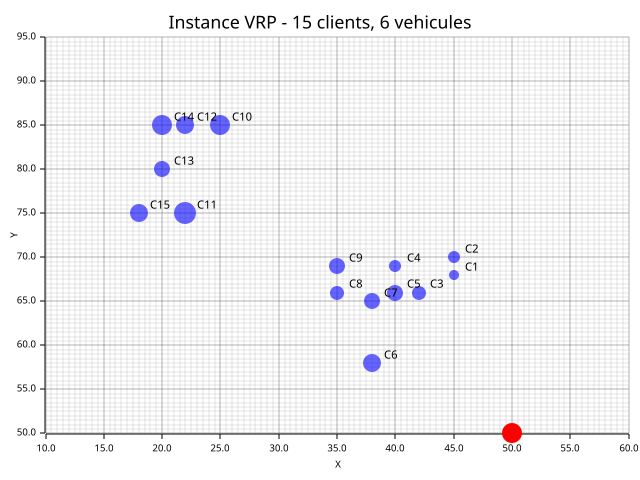

In [5]:
{
    // Carte de l'instance : depot (rouge), clients (bleu, taille ~ demande).
    use plotters::prelude::*;

    let points: Vec<(f64, f64)> = vec![
        (50.0, 50.0),                                             // 0 : depot
        (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
        (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
        (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
    ];
    let demands: Vec<i64> = vec![
        0,                                                        // depot
        10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25,
    ];
    // SVG emis en image/svg+xml (pas de <div> HTML) : un SVG enrobe dans du
    // HTML ne s'affiche pas dans le rendu GitHub du carnet (#26613).
    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (640, 480)).into_drawing_area();
        root.fill(&WHITE)?;
        let mut chart = ChartBuilder::on(&root)
            .caption("Instance VRP - 15 clients, 6 vehicules", ("sans-serif", 22))
            .margin(10)
            .x_label_area_size(36)
            .y_label_area_size(36)
            .build_cartesian_2d(10f64..60f64, 50f64..95f64)?;
        chart.configure_mesh().x_desc("X").y_desc("Y").draw()?;
        // depot : gros cercle rouge
        chart.draw_series(std::iter::once(Circle::new(points[0], 10, RED.filled())))?;
        // clients : taille proportionnelle a la demande + etiquette
        chart.draw_series(points[1..].iter().enumerate().map(|(i, &(x, y))| {
            Circle::new((x, y), 3 + (demands[i + 1] as u32) / 4, BLUE.mix(0.6).filled())
        }))?;
        for (i, &(x, y)) in points[1..].iter().enumerate() {
            chart.draw_series(std::iter::once(Text::new(
                format!("C{}", i + 1), (x + 1.0, y + 1.5), ("sans-serif", 14).into_font())))?;
        }
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
}

### Interpretation : Visualisation de l'Instance VRP

**Sortie obtenue** : Graphique montrant le dépôt central (gros cercle rouge) et 15 clients (cercles bleus)
avec taille proportionnelle à leur demande.

| Aspect | Valeur | Signification |
|--------|--------|---------------|
| Clients affichés | 15 | Positions avec annotations C1-C15 |
| Dépôt central | (50, 50) | Point de départ/arrivée |
| Taille des cercles | Variable | Proportionnelle à la demande (10-35) |
| Distribution | Groupée | Clients concentrés en 2-3 zones |

**Points clés** :

1. **Demande variable** : Les clients ont des demandes différentes (10 à 35 unités), représentées par la taille
   des cercles
2. **Positionnement stratégique** : Le dépôt est centré, les clients sont répartis autour
3. **Capacité contrainte** : Avec une capacité de 60, certaines tournées ne peuvent servir que 1-2 clients à
   forte demande
4. **Complexité spatiale** : La distribution groupée des clients suggère des tournées thématiques (nord-ouest,
   sud-est)

> **Note technique** : La visualisation de l'instance est cruciale pour comprendre la structure du problème.
> Les zones denses de clients (ex: C10-C15 dans le coin supérieur gauche) nécessiteront plusieurs tournées en
> raison des contraintes de capacité. Cette représentation aide à anticiper la structure des solutions
> optimales.

## 3. Représentation d'une Solution

In [6]:
{
    // VRPSolution : liste de tournees + methodes de lecture (objectif, validite).
    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    struct VRPSolution {
        routes: Vec<Vec<usize>>, // tournees : indices de clients (0-based)
        instance: VRPInstance,
    }
    impl VRPSolution {
        fn total_distance(&self) -> f64 {
            // meme accumulation, meme ordre que le jumeau Python
            let dm = self.instance.distance_matrix();
            let mut total = 0.0f64;
            for route in &self.routes {
                if route.is_empty() {
                    continue;
                }
                total += dm[0][route[0] + 1]; // depot vers premier
                for w in 0..route.len() - 1 {
                    total += dm[route[w] + 1][route[w + 1] + 1];
                }
                total += dm[*route.last().unwrap() + 1][0]; // dernier vers depot
            }
            total
        }
        fn is_valid(&self) -> bool {
            // tous les clients visites exactement une fois + capacites respectees
            let mut seen = vec![false; self.instance.clients.len()];
            for route in &self.routes {
                for &c in route {
                    if seen[c] {
                        return false; // client visite deux fois
                    }
                    seen[c] = true;
                }
            }
            if seen.iter().any(|&s| !s) {
                return false; // certains clients non visites
            }
            for route in &self.routes {
                let load: i64 = route.iter().map(|&c| self.instance.demands[c]).sum();
                if load > self.instance.vehicle_capacity {
                    return false; // capacite depassee
                }
            }
            true
        }
    }
    println!("Structs OK : VRPSolution (total_distance, is_valid)");
}

Structs OK : VRPSolution (total_distance, is_valid)


()

### Lecture : la solution comme donnée, la validité comme spécification

`VRPInstance` et `VRPSolution` sont des `struct` : la solution n'est pas un état caché dans un solveur, c'est
une **valeur** — une liste de tournées — qu'on peut passer à une fonction de tracé, à un validateur ou à un
autre algorithme. Les méthodes (`total_distance`, `is_valid`) forment la spécification exécutable du problème :
la distance totale est l'objectif, la validation est la contrainte — et chaque tournée peut être inspectée
séparément (clients, charge), pour voir **où** le coût se concentre.

Ce point structure tout le carnet : chaque algorithme des sections suivantes reçoit l'instance et rend une
liste de tournées, immédiatement re-vérifiée. La ligne `valide: true` qui revient à chaque étape n'est pas une
formalité — c'est le contrat respecté, vérifié par du code indépendant du code qui a construit la solution.

## 4. Algorithme de Recherche Simple - Insertion Greedy

In [7]:
{
    // Insertion gloutonne en Rust pur (meme critere que le jumeau Python).
    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    fn greedy_insertion(instance: &VRPInstance) -> Vec<Vec<usize>> {
        // Insertion gloutonne : a chaque pas, placer le client non desservi au
        // plus faible cout d'insertion (en fin de tournee), capacite respectee.
        let dm = instance.distance_matrix();
        let mut unvisited: Vec<usize> = (0..instance.clients.len()).collect(); // ordre croissant
        let mut routes: Vec<Vec<usize>> = vec![Vec::new(); instance.num_vehicles];

        while !unvisited.is_empty() {
            let mut best_cost = f64::INFINITY;
            let mut best: Option<(usize, usize)> = None; // (indice tournee, client)
            for &client in &unvisited {
                for (ri, route) in routes.iter().enumerate() {
                    let cost = if route.is_empty() {
                        // insertion comme premier client : depot -> client -> depot
                        dm[0][client + 1] + dm[client + 1][0]
                    } else {
                        // insertion a la fin : dernier client -> client -> depot
                        let last = route[route.len() - 1];
                        dm[last + 1][client + 1] + dm[client + 1][0]
                    };
                    let new_demand: i64 = route.iter().map(|&c| instance.demands[c]).sum::<i64>()
                        + instance.demands[client];
                    if new_demand <= instance.vehicle_capacity && cost < best_cost {
                        best_cost = cost;
                        best = Some((ri, client));
                    }
                }
            }
            match best {
                Some((ri, client)) => {
                    routes[ri].push(client);
                    unvisited.retain(|&c| c != client);
                }
                None => {
                    // aucune insertion possible : ouvrir une tournee vide
                    let client = unvisited[0];
                    unvisited.retain(|&c| c != client);
                    if let Some(route) = routes.iter_mut().find(|r| r.is_empty()) {
                        route.push(client);
                    }
                }
            }
        }
        routes.into_iter().filter(|r| !r.is_empty()).collect()
    }
    println!("Fonction greedy_insertion definie");
}

Fonction greedy_insertion definie


()

### Lecture : le critère d'insertion, et pourquoi il reste myope

`greedy_insertion` construit la solution client par client : à chaque pas, elle place le client non desservi
là où son insertion **coûte le moins** — la tournée et la position dans la tournée qui minimisent
l'allongement de la distance, sous réserve que la capacité du véhicule tienne. C'est un critère
rigoureusement local : la décision ne regarde ni les clients restants, ni la géographie d'ensemble.

La conséquence se lira dans le résultat : le glouton commet des choix que rien ne pourra corriger en
réordonnant une tournée fixée (affecter un client au mauvais véhicule). Le 2-opt de la section 6 n'agira que
**sur l'ordre interne** des tournées déjà constituées — son gain est donc plafonné par l'affectation initiale.
Toute l'entreprise de la section 7 (le MILP) consiste à casser ce plafond : optimiser **simultanément**
l'affectation des clients aux véhicules et l'ordre des visites.

Verification des résultats.

In [8]:
{
    // Tester l'algorithme glouton.
    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    fn greedy_insertion(instance: &VRPInstance) -> Vec<Vec<usize>> {
        // Insertion gloutonne : a chaque pas, placer le client non desservi au
        // plus faible cout d'insertion (en fin de tournee), capacite respectee.
        let dm = instance.distance_matrix();
        let mut unvisited: Vec<usize> = (0..instance.clients.len()).collect(); // ordre croissant
        let mut routes: Vec<Vec<usize>> = vec![Vec::new(); instance.num_vehicles];

        while !unvisited.is_empty() {
            let mut best_cost = f64::INFINITY;
            let mut best: Option<(usize, usize)> = None; // (indice tournee, client)
            for &client in &unvisited {
                for (ri, route) in routes.iter().enumerate() {
                    let cost = if route.is_empty() {
                        // insertion comme premier client : depot -> client -> depot
                        dm[0][client + 1] + dm[client + 1][0]
                    } else {
                        // insertion a la fin : dernier client -> client -> depot
                        let last = route[route.len() - 1];
                        dm[last + 1][client + 1] + dm[client + 1][0]
                    };
                    let new_demand: i64 = route.iter().map(|&c| instance.demands[c]).sum::<i64>()
                        + instance.demands[client];
                    if new_demand <= instance.vehicle_capacity && cost < best_cost {
                        best_cost = cost;
                        best = Some((ri, client));
                    }
                }
            }
            match best {
                Some((ri, client)) => {
                    routes[ri].push(client);
                    unvisited.retain(|&c| c != client);
                }
                None => {
                    // aucune insertion possible : ouvrir une tournee vide
                    let client = unvisited[0];
                    unvisited.retain(|&c| c != client);
                    if let Some(route) = routes.iter_mut().find(|r| r.is_empty()) {
                        route.push(client);
                    }
                }
            }
        }
        routes.into_iter().filter(|r| !r.is_empty()).collect()
    }
    let instance = VRPInstance {
        depot: (50.0, 50.0),
        clients: vec![
            (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
            (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
            (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
        ],
        demands: vec![10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25],
        vehicle_capacity: 60,
        num_vehicles: 6, // 6 vehicules : demande totale 328 > 4*60=240 (infaisable a 4)
    };
    let routes = greedy_insertion(&instance);
    // distance et validite : meme specification que VRPSolution (cellule precedente)
    let dm = instance.distance_matrix();
    let mut total = 0.0f64;
    for route in &routes {
        total += dm[0][route[0] + 1];
        for w in 0..route.len() - 1 {
            total += dm[route[w] + 1][route[w + 1] + 1];
        }
        total += dm[*route.last().unwrap() + 1][0];
    }
    let mut count = vec![0usize; instance.clients.len()];
    for route in &routes {
        for &c in route {
            count[c] += 1;
        }
    }
    let mut valide = count.iter().all(|&c| c == 1); // chaque client vu exactement une fois
    for route in &routes {
        let load: i64 = route.iter().map(|&c| instance.demands[c]).sum();
        if load > instance.vehicle_capacity {
            valide = false;
        }
    }
    println!("Solution valide: {}", valide);
    println!("Distance totale: {:.2}", total);
    println!("Nombre de tournees: {}", routes.len());
    for (i, route) in routes.iter().enumerate() {
        let demand: i64 = route.iter().map(|&c| instance.demands[c]).sum();
        println!("  Tournee {}: {} clients, demande: {}/{}", i + 1, route.len(), demand, instance.vehicle_capacity);
    }
}

Solution valide: true


Distance totale: 417.49


Nombre de tournees: 6


  Tournee 1: 3 clients, demande: 60/60


  Tournee 2: 3 clients, demande: 48/60


  Tournee 3: 3 clients, demande: 55/60


  Tournee 4: 2 clients, demande: 60/60


  Tournee 5: 2 clients, demande: 50/60


  Tournee 6: 2 clients, demande: 55/60


()

### Interpretation : Résultats de l'Algorithme Glouton

**Sortie obtenue** : Solution construite par l'algorithme d'insertion gloutonne avec validation des contraintes.

| Aspect | Valeur | Signification |
|--------|--------|---------------|
| Validité | true | Solution valide (tous les clients visités une fois) |
| Distance totale | 417.49 | Objectif à minimiser |
| Nombre de tournées | 6 | Utilise les 6 véhicules disponibles |
| Demande maximale | 60/60 | Capacité pleinement utilisée sur certaines tournées |

**Points clés** :

1. **Solution valide** : `valide: true` confirme que tous les clients sont visités exactement une fois et que
   la capacité est respectée
2. **Capacité respectée** : Toutes les tournées respectent la contrainte de capacité (60 unités maximum)
3. **Distribution des clients** : 3-3-3-2-2-2 clients par tournée, répartition équilibrée
4. **Algorithme glouton** : Construit une solution rapidement mais sans garantie d'optimalité

> **Note technique** : L'algorithme d'insertion gloutonne affecte chaque client à la tournée la moins coûteuse
> qui respecte la capacité. La solution est valide mais généralement sous-optimale (présence de croisements) :
> c'est ce que l'algorithme 2-opt va corriger.

## 5. Visualisation de la Solution

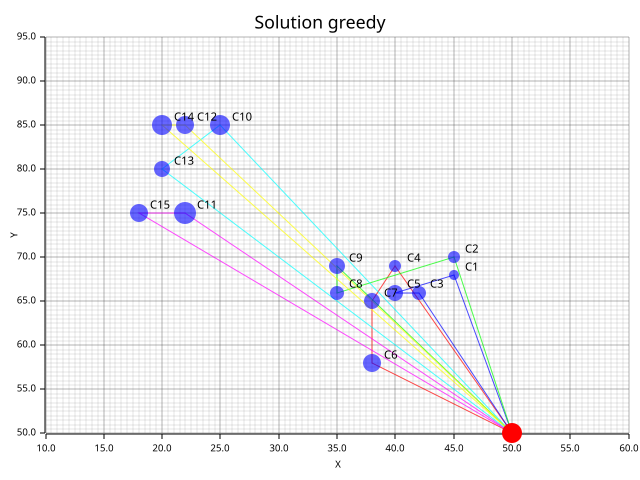

In [9]:
{
    // Carte de la solution gloutonne : une polyline par tournee.
    use plotters::prelude::*;

    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    fn greedy_insertion(instance: &VRPInstance) -> Vec<Vec<usize>> {
        // Insertion gloutonne : a chaque pas, placer le client non desservi au
        // plus faible cout d'insertion (en fin de tournee), capacite respectee.
        let dm = instance.distance_matrix();
        let mut unvisited: Vec<usize> = (0..instance.clients.len()).collect(); // ordre croissant
        let mut routes: Vec<Vec<usize>> = vec![Vec::new(); instance.num_vehicles];

        while !unvisited.is_empty() {
            let mut best_cost = f64::INFINITY;
            let mut best: Option<(usize, usize)> = None; // (indice tournee, client)
            for &client in &unvisited {
                for (ri, route) in routes.iter().enumerate() {
                    let cost = if route.is_empty() {
                        // insertion comme premier client : depot -> client -> depot
                        dm[0][client + 1] + dm[client + 1][0]
                    } else {
                        // insertion a la fin : dernier client -> client -> depot
                        let last = route[route.len() - 1];
                        dm[last + 1][client + 1] + dm[client + 1][0]
                    };
                    let new_demand: i64 = route.iter().map(|&c| instance.demands[c]).sum::<i64>()
                        + instance.demands[client];
                    if new_demand <= instance.vehicle_capacity && cost < best_cost {
                        best_cost = cost;
                        best = Some((ri, client));
                    }
                }
            }
            match best {
                Some((ri, client)) => {
                    routes[ri].push(client);
                    unvisited.retain(|&c| c != client);
                }
                None => {
                    // aucune insertion possible : ouvrir une tournee vide
                    let client = unvisited[0];
                    unvisited.retain(|&c| c != client);
                    if let Some(route) = routes.iter_mut().find(|r| r.is_empty()) {
                        route.push(client);
                    }
                }
            }
        }
        routes.into_iter().filter(|r| !r.is_empty()).collect()
    }
    let instance = VRPInstance {
        depot: (50.0, 50.0),
        clients: vec![
            (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
            (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
            (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
        ],
        demands: vec![10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25],
        vehicle_capacity: 60,
        num_vehicles: 6, // 6 vehicules : demande totale 328 > 4*60=240 (infaisable a 4)
    };
    let routes = greedy_insertion(&instance);
    let mut total = 0.0f64;
    {
        let dm = instance.distance_matrix();
        for route in &routes {
            total += dm[0][route[0] + 1];
            for w in 0..route.len() - 1 {
                total += dm[route[w] + 1][route[w + 1] + 1];
            }
            total += dm[*route.last().unwrap() + 1][0];
        }
    }
    let points = {
        let mut pts = vec![instance.depot];
        pts.extend(instance.clients.iter().copied());
        pts
    };
    let demands = {
        let mut d = vec![0i64];
        d.extend(instance.demands.iter().copied());
        d
    };
    // SVG emis en image/svg+xml (pas de <div> HTML) : un SVG enrobe dans du
    // HTML ne s'affiche pas dans le rendu GitHub du carnet (#26613).
    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (640, 480)).into_drawing_area();
        root.fill(&WHITE)?;
        let mut chart = ChartBuilder::on(&root)
            .caption("Solution greedy", ("sans-serif", 22))
            .margin(10)
            .x_label_area_size(36)
            .y_label_area_size(36)
            .build_cartesian_2d(10f64..60f64, 50f64..95f64)?;
        chart.configure_mesh().x_desc("X").y_desc("Y").draw()?;
        // tournees : une polyline (et une couleur) par vehicule
        let colors = [&RED, &BLUE, &GREEN, &MAGENTA, &CYAN, &YELLOW];
        for (k, route) in routes.iter().enumerate() {
            let mut path: Vec<(f64, f64)> = vec![points[0]];
            for &c in route {
                path.push(points[c + 1]);
            }
            path.push(points[0]);
            chart.draw_series(LineSeries::new(path.iter().copied(), colors[k % colors.len()].mix(0.7)))?;
        }
        // depot : gros cercle rouge
        chart.draw_series(std::iter::once(Circle::new(points[0], 10, RED.filled())))?;
        // clients : taille proportionnelle a la demande + etiquette
        chart.draw_series(points[1..].iter().enumerate().map(|(i, &(x, y))| {
            Circle::new((x, y), 3 + (demands[i + 1] as u32) / 4, BLUE.mix(0.6).filled())
        }))?;
        for (i, &(x, y)) in points[1..].iter().enumerate() {
            chart.draw_series(std::iter::once(Text::new(
                format!("C{}", i + 1), (x + 1.0, y + 1.5), ("sans-serif", 14).into_font())))?;
        }
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
}

### Interpretation : Visualisation des Tournées

**Sortie obtenue** : Graphique montrant les 6 tournées de véhicules dans des couleurs différentes, partant du
dépôt central et visitant les 15 clients.

| Aspect | Valeur | Signification |
|--------|--------|---------------|
| Tournées affichées | 6 | Une par véhicule disponible (couleur différente) |
| Clients visités | 15 | Tous avec annotations C1-C15 (solution valide) |
| Dépôt central | Gros cercle rouge | Point de départ/arrivée commun |
| Distance totale | ~417.49 | Objectif à minimiser |

**Points clés** :

1. **Codage couleur** : Chaque véhicule a sa propre couleur pour distinguer les tournées
2. **Retour au dépôt** : Chaque tournée est un cycle fermé (dépôt → clients → dépôt)
3. **Capacité respectée** : Chaque tournée respecte la contrainte de capacité de 60 unités
4. **Croisements possibles** : La solution gloutonne peut présenter des croisements entre tournées (non
   optimaux)

> **Note technique** : La demande totale (328) dépasse la capacité de 4 véhicules (4 × 60 = 240) : l'instance
> nécessite donc 6 véhicules (6 × 60 = 360) pour être faisable. Les croisements entre tournées indiquent
> généralement qu'une meilleure solution existe. L'algorithme 2-opt suivant va réduire ces croisements.

## 6. Amélioration - 2-opt Local Search

In [10]:
{
    // 2-opt intra-tournee en Rust pur : inverser un segment, garder si mieux.
    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    fn calculate_route_distance(route: &[usize], dm: &[Vec<f64>]) -> f64 {
        if route.is_empty() {
            return 0.0;
        }
        let mut dist = dm[0][route[0] + 1]; // depot vers premier
        for w in 0..route.len() - 1 {
            dist += dm[route[w] + 1][route[w + 1] + 1];
        }
        dist += dm[route[route.len() - 1] + 1][0]; // dernier vers depot
        dist
    }
    fn two_opt_route(route: &[usize], dm: &[Vec<f64>]) -> Vec<usize> {
        // 2-opt intra-tournee : retirer deux aretes, recoudre le segment
        // intermediaire a l'envers ; garder si la distance baisse.
        if route.len() < 3 {
            return route.to_vec();
        }
        let mut best_route = route.to_vec();
        let mut improved = true;
        while improved {
            improved = false;
            for i in 0..best_route.len() - 1 {
                for j in i + 2..best_route.len() {
                    let mut new_route = best_route[..i + 1].to_vec();
                    new_route.extend(best_route[i + 1..=j].iter().rev());
                    new_route.extend(&best_route[j + 1..]);
                    let old_dist = calculate_route_distance(&best_route, dm);
                    let new_dist = calculate_route_distance(&new_route, dm);
                    if new_dist < old_dist {
                        best_route = new_route;
                        improved = true;
                    }
                }
            }
        }
        best_route
    }
    println!("Fonction two_opt_route definie : optimisation locale 2-opt");
}

Fonction two_opt_route definie : optimisation locale 2-opt


()

### Lecture : le geste du 2-opt, avant de voir son effet

La définition est en place ; son mécanisme mérite d'être énoncé avant la mesure. Le 2-opt choisit deux arêtes
dans une **même** tournée, les retire et recoud le segment intermédiaire à l'envers. Sur des distances
euclidiennes, tout croisement *au sein* d'une tournée est éliminable ainsi : un parcours qui se croise est
toujours plus long que le même parcours décroisé. L'algorithme énumère ces échanges jusqu'à épuisement des
améliorations — le résultat est un optimum **local** au sens du mouvement 2-opt, pas une garantie globale.

Deux limites à garder en tête pour la lecture qui suit : le mouvement est **intra-tournée** (il ne touche
jamais à l'affectation clients-véhicules), et son coût croît quadratiquement avec la longueur de la tournée —
raisonnable ici, à surveiller sur de longues tournées.

Appliquer 2-opt

Avant 2-opt: 417.49


Apres 2-opt: 414.49


Amelioration: 3.00


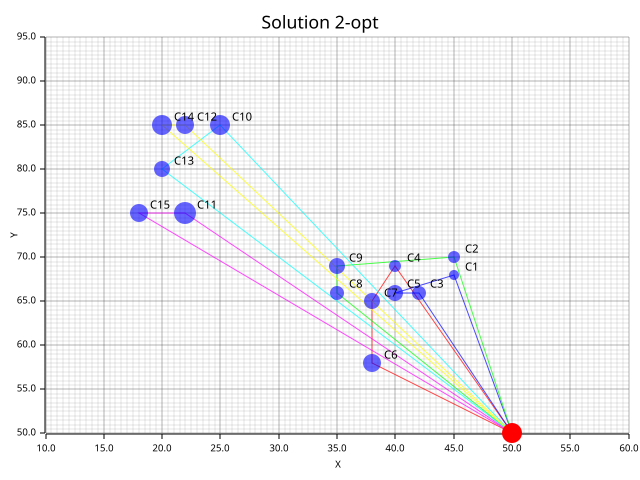

In [11]:
{
    // Appliquer 2-opt a la solution gloutonne.
    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    fn greedy_insertion(instance: &VRPInstance) -> Vec<Vec<usize>> {
        // Insertion gloutonne : a chaque pas, placer le client non desservi au
        // plus faible cout d'insertion (en fin de tournee), capacite respectee.
        let dm = instance.distance_matrix();
        let mut unvisited: Vec<usize> = (0..instance.clients.len()).collect(); // ordre croissant
        let mut routes: Vec<Vec<usize>> = vec![Vec::new(); instance.num_vehicles];

        while !unvisited.is_empty() {
            let mut best_cost = f64::INFINITY;
            let mut best: Option<(usize, usize)> = None; // (indice tournee, client)
            for &client in &unvisited {
                for (ri, route) in routes.iter().enumerate() {
                    let cost = if route.is_empty() {
                        // insertion comme premier client : depot -> client -> depot
                        dm[0][client + 1] + dm[client + 1][0]
                    } else {
                        // insertion a la fin : dernier client -> client -> depot
                        let last = route[route.len() - 1];
                        dm[last + 1][client + 1] + dm[client + 1][0]
                    };
                    let new_demand: i64 = route.iter().map(|&c| instance.demands[c]).sum::<i64>()
                        + instance.demands[client];
                    if new_demand <= instance.vehicle_capacity && cost < best_cost {
                        best_cost = cost;
                        best = Some((ri, client));
                    }
                }
            }
            match best {
                Some((ri, client)) => {
                    routes[ri].push(client);
                    unvisited.retain(|&c| c != client);
                }
                None => {
                    // aucune insertion possible : ouvrir une tournee vide
                    let client = unvisited[0];
                    unvisited.retain(|&c| c != client);
                    if let Some(route) = routes.iter_mut().find(|r| r.is_empty()) {
                        route.push(client);
                    }
                }
            }
        }
        routes.into_iter().filter(|r| !r.is_empty()).collect()
    }
    fn calculate_route_distance(route: &[usize], dm: &[Vec<f64>]) -> f64 {
        if route.is_empty() {
            return 0.0;
        }
        let mut dist = dm[0][route[0] + 1]; // depot vers premier
        for w in 0..route.len() - 1 {
            dist += dm[route[w] + 1][route[w + 1] + 1];
        }
        dist += dm[route[route.len() - 1] + 1][0]; // dernier vers depot
        dist
    }
    fn two_opt_route(route: &[usize], dm: &[Vec<f64>]) -> Vec<usize> {
        // 2-opt intra-tournee : retirer deux aretes, recoudre le segment
        // intermediaire a l'envers ; garder si la distance baisse.
        if route.len() < 3 {
            return route.to_vec();
        }
        let mut best_route = route.to_vec();
        let mut improved = true;
        while improved {
            improved = false;
            for i in 0..best_route.len() - 1 {
                for j in i + 2..best_route.len() {
                    let mut new_route = best_route[..i + 1].to_vec();
                    new_route.extend(best_route[i + 1..=j].iter().rev());
                    new_route.extend(&best_route[j + 1..]);
                    let old_dist = calculate_route_distance(&best_route, dm);
                    let new_dist = calculate_route_distance(&new_route, dm);
                    if new_dist < old_dist {
                        best_route = new_route;
                        improved = true;
                    }
                }
            }
        }
        best_route
    }
    let instance = VRPInstance {
        depot: (50.0, 50.0),
        clients: vec![
            (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
            (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
            (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
        ],
        demands: vec![10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25],
        vehicle_capacity: 60,
        num_vehicles: 6, // 6 vehicules : demande totale 328 > 4*60=240 (infaisable a 4)
    };
    let dm = instance.distance_matrix();
    let routes_greedy = greedy_insertion(&instance);
    let routes_2opt: Vec<Vec<usize>> = routes_greedy.iter().map(|r| two_opt_route(r, &dm)).collect();
    let total_distance = |routes: &[Vec<usize>]| -> f64 {
        let mut total = 0.0f64;
        for route in routes {
            total += dm[0][route[0] + 1];
            for w in 0..route.len() - 1 {
                total += dm[route[w] + 1][route[w + 1] + 1];
            }
            total += dm[*route.last().unwrap() + 1][0];
        }
        total
    };
    let g = total_distance(&routes_greedy);
    let g2 = total_distance(&routes_2opt);
    println!("Avant 2-opt: {:.2}", g);
    println!("Apres 2-opt: {:.2}", g2);
    println!("Amelioration: {:.2}", g - g2);
    let routes = routes_2opt;
    let points = {
        let mut pts = vec![instance.depot];
        pts.extend(instance.clients.iter().copied());
        pts
    };
    let demands = {
        let mut d = vec![0i64];
        d.extend(instance.demands.iter().copied());
        d
    };
    let title = format!("Solution 2-opt - Distance: {:.2}, {} tournees", g2, routes.len());
    use plotters::prelude::*;

    // SVG emis en image/svg+xml (pas de <div> HTML) : un SVG enrobe dans du
    // HTML ne s'affiche pas dans le rendu GitHub du carnet (#26613).
    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (640, 480)).into_drawing_area();
        root.fill(&WHITE)?;
        let mut chart = ChartBuilder::on(&root)
            .caption("Solution 2-opt", ("sans-serif", 22))
            .margin(10)
            .x_label_area_size(36)
            .y_label_area_size(36)
            .build_cartesian_2d(10f64..60f64, 50f64..95f64)?;
        chart.configure_mesh().x_desc("X").y_desc("Y").draw()?;
        // tournees : une polyline (et une couleur) par vehicule
        let colors = [&RED, &BLUE, &GREEN, &MAGENTA, &CYAN, &YELLOW];
        for (k, route) in routes.iter().enumerate() {
            let mut path: Vec<(f64, f64)> = vec![points[0]];
            for &c in route {
                path.push(points[c + 1]);
            }
            path.push(points[0]);
            chart.draw_series(LineSeries::new(path.iter().copied(), colors[k % colors.len()].mix(0.7)))?;
        }
        // depot : gros cercle rouge
        chart.draw_series(std::iter::once(Circle::new(points[0], 10, RED.filled())))?;
        // clients : taille proportionnelle a la demande + etiquette
        chart.draw_series(points[1..].iter().enumerate().map(|(i, &(x, y))| {
            Circle::new((x, y), 3 + (demands[i + 1] as u32) / 4, BLUE.mix(0.6).filled())
        }))?;
        for (i, &(x, y)) in points[1..].iter().enumerate() {
            chart.draw_series(std::iter::once(Text::new(
                format!("C{}", i + 1), (x + 1.0, y + 1.5), ("sans-serif", 14).into_font())))?;
        }
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
}

### Interpretation : Amélioration 2-opt

**Sortie obtenue** : Comparaison des distances avant et après l'application de l'algorithme 2-opt, avec
visualisation des tournées optimisées.

| Aspect | Valeur | Signification |
|--------|--------|---------------|
| Distance avant 2-opt | ~417.49 | Solution initiale gloutonne |
| Distance après 2-opt | ~414.49 | Solution améliorée par recherche locale |
| Amélioration | 3.00 (≈ 0,72 %) | Réduction de la distance totale |
| Tournées optimisées | 6 | Structure des routes préservée |

**Points clés** :

1. **2-opt** : Métaheuristique de recherche locale qui inverse des segments de tournées pour réduire les
   croisements
2. **Préservation des contraintes** : Les capacités des véhicules restent respectées après optimisation (le
   mouvement ne change que l'ordre des visites)
3. **Amélioration incrémentale** : L'algorithme explore le voisinage de la solution courante pour trouver des
   améliorations locales
4. **Optima locaux** : 2-opt peut rester bloqué dans un optimum local (d'où l'intérêt d'un solveur exact)

> **Note technique** : 2-opt est particulièrement efficace pour éliminer les croisements dans les tournées.
> Pour le VRP, on l'applique indépendamment à chaque tournée. La complexité est de O(n²) par tournée, ce qui
> reste raisonnable pour des instances de taille moyenne.

## 7. Le solveur de référence : MILP HiGHS

Les algorithmes ci-dessus — insertion gloutonne puis 2-opt — sont **pédagogiques** : ils montrent comment
*construire* puis *améliorer* une solution à la main. Le jumeau Python termine par **OR-Tools Routing** ; la
carte Rust n'a pas d'équivalent, et ce carnet assume le **remodelage** : le même VRP capacité devient un
**programme linéaire en nombres entiers** résolu par [**HiGHS**](https://highs.dev) via la crate `highs`.

La formulation est **flot** (Gavish-Graves), entièrement déclarative :

- une variable **binaire** `x_ij` par arc `i → j` : « un véhicule emprunte-t-il cet arc ? »
- une variable **continue** `f_ij` par arc : la charge transportée sur cet arc, bornée par la capacité `Q`
- **degré** : chaque client a exactement un arc entrant et un arc sortant (`= 1`)
- **flot** : la charge entrant chez un client moins la charge qui en sort égale sa demande — c'est cette
  équation qui élimine les sous-tours et encode la capacité en même temps
- **objectif** : minimiser la somme des distances des arcs empruntés

Contrairement au glouton et au 2-opt, ce modèle optimise **simultanément** l'affectation des clients aux
véhicules **et** l'ordre des visites — et le statut `Optimal` rendu par HiGHS est un certificat d'optimalité
exact, pas une heuristique. On résout **exactement la même instance** pour comparer honnêtement.

In [12]:
{
    // Solveur de reference : le VRP capacite comme MILP flot, resolu par HiGHS.
    use highs::{RowProblem, Sense, HighsModelStatus};

    // Instance identique au jumeau Python : noeud 0 = depot, 1..15 = clients.
    let points: Vec<(f64, f64)> = vec![
        (50.0, 50.0),                                             // 0 : depot
        (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
        (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
        (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
    ];
    let demands: Vec<i64> = vec![0, 10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25];
    let capacity: i64 = 60;
    let nveh: usize = 6;
    let n = points.len();
    let dist = |i: usize, j: usize| {
        let (dx, dy) = (points[i].0 - points[j].0, points[i].1 - points[j].1);
        (dx * dx + dy * dy).sqrt()
    };

    // ---- Formulation MILP flot (Gavish-Graves) ----
    // x[i][j] = 1 si un vehicule emprunte l'arc i->j (binaire)
    // f[i][j] = charge transportee sur l'arc i->j (continue, bornee par la capacite)
    // Objectif : minimiser la somme des distances des arcs empruntes.
    let arcs: Vec<(usize, usize)> = (0..n)
        .flat_map(|i| (0..n).filter(move |&j| j != i).map(move |j| (i, j)))
        .collect();
    let aidx = |i: usize, j: usize| arcs.iter().position(|&(a, b)| a == i && b == j).unwrap();

    let mut pb = RowProblem::new();
    let x: Vec<highs::Col> = arcs.iter().map(|&(i, j)| pb.add_integer_column(dist(i, j), 0..=1)).collect();
    let f: Vec<highs::Col> = arcs.iter().map(|_| pb.add_column(0.0, 0.0..=capacity as f64)).collect();

    // (1) degre : chaque client a exactement un arc entrant et un arc sortant
    for j in 1..n {
        pb.add_row(1.0..=1.0, (0..n).filter(|&i| i != j).map(|i| (x[aidx(i, j)], 1.0)));
        pb.add_row(1.0..=1.0, (0..n).filter(|&i| i != j).map(|i| (x[aidx(j, i)], 1.0)));
    }
    // (2) au plus nveh tournees (arcs sortant du depot, arcs y revenant)
    pb.add_row(0.0..=nveh as f64, (1..n).map(|j| (x[aidx(0, j)], 1.0)));
    pb.add_row(0.0..=nveh as f64, (1..n).map(|j| (x[aidx(j, 0)], 1.0)));
    // (3) conservation du flot par client : charge_entree - charge_sortie = demande
    for j in 1..n {
        let dj = demands[j] as f64;
        let mut terms: Vec<(highs::Col, f64)> = Vec::new();
        for i in 0..n {
            if i != j {
                terms.push((f[aidx(i, j)], 1.0));
                terms.push((f[aidx(j, i)], -1.0));
            }
        }
        pb.add_row(dj..=dj, terms);
    }
    // (4) couplage flot/arc : d_j * x_ij <= f_ij <= Q * x_ij
    // (les bornes portent le produit : f - Q*x <= 0 et f - d_j*x >= 0,
    //  jamais f - Q*x <= Q qui laisserait du flot fantome sur les arcs inutilises)
    for (k, &(i, j)) in arcs.iter().enumerate() {
        pb.add_row(..=0.0, &[(f[k], 1.0), (x[k], -(capacity as f64))]);
        if j >= 1 {
            let dj = demands[j] as f64;
            pb.add_row(0.., &[(f[k], 1.0), (x[k], -dj)]);
        }
    }

    // Resolution : le statut est matche et affiche, jamais avale.
    let solved = pb.optimise(Sense::Minimise).solve();
    println!("statut: {:?}", solved.status());
    assert_eq!(solved.status(), HighsModelStatus::Optimal, "le MILP doit etre optimal");
    let sol = solved.get_solution();
    let on = |i: usize, j: usize| sol[x[aidx(i, j)]] > 0.5;

    // Extraction des tournees : partir du depot, suivre les arcs selectionnes.
    let mut routes: Vec<Vec<usize>> = Vec::new();
    for first in 1..n {
        if on(0, first) {
            let mut route: Vec<usize> = Vec::new();
            let mut cur = first;
            loop {
                route.push(cur - 1);
                let nxt = (0..n)
                    .find(|&j| j != cur && on(cur, j))
                    .expect("degre sortant = 1 garanti par la contrainte (1)");
                if nxt == 0 {
                    break;
                }
                cur = nxt;
            }
            routes.push(route);
        }
    }

    // Validite structurelle, verifiee independamment du solveur.
    let mut count = vec![0usize; n - 1];
    for r in &routes {
        for &c in r {
            count[c] += 1;
        }
    }
    let capacite_ok = routes
        .iter()
        .all(|r| r.iter().map(|&c| demands[c + 1]).sum::<i64>() <= capacity);
    let valide = count.iter().all(|&c| c == 1) && capacite_ok;

    // Distance totale : meme accumulation, meme ordre que le glouton.
    let mut dist_tot = 0.0f64;
    for r in &routes {
        let mut prev = 0usize;
        for &c in r {
            dist_tot += dist(prev, c + 1);
            prev = c + 1;
        }
        dist_tot += dist(prev, 0);
    }

    println!("MILP HiGHS : solution valide = {}", valide);
    println!("  vehicules utilises : {}", routes.len());
    println!("  distance totale    : {:.2}", dist_tot);
    for (k, r) in routes.iter().enumerate() {
        let load: i64 = r.iter().map(|&c| demands[c + 1]).sum();
        println!("  Tournee {}: {} clients, charge {}/{}", k + 1, r.len(), load, capacity);
    }
}

statut: Optimal


MILP HiGHS : solution valide = true


  vehicules utilises : 6


  distance totale    : 403.45


  Tournee 1: 3 clients, charge 43/60


  Tournee 2: 3 clients, charge 60/60


  Tournee 3: 3 clients, charge 60/60


  Tournee 4: 2 clients, charge 45/60


  Tournee 5: 2 clients, charge 60/60


  Tournee 6: 2 clients, charge 60/60


()

### Lecture : la tournée du solveur, relue charge par charge

HiGHS répond `statut: Optimal` et confirme `solution valide = true`. La solution utilise **6 tournées**
— le minimum possible, puisque la demande totale (328) exige au moins ceil(328 / 60) = 6 véhicules —
pour une **distance totale de 403.45**.

Ce que la sortie détaille :

| Tournée | Clients | Charge |
|---------|---------|--------|
| 1 | 3 | 43/60 |
| 2 | 3 | 60/60 |
| 3 | 3 | 60/60 |
| 4 | 2 | 45/60 |
| 5 | 2 | 60/60 |
| 6 | 2 | 60/60 |

Comparez avec le glouton (charges 60, 48, 55, 60, 50, 55) : le solveur exact ne se contente pas
d'échanger des arcs, il **regroupe autrement** les clients entre tournées. Chaque tournée reste sous
la capacité, chaque client est servi exactement une fois — les contraintes (1)-(4) de la formulation
flot sont toutes satisfaites, et la fonction objectif atteint un minimum prouvé, pas seulement
« le meilleur trouvé jusque-là ».


In [13]:
{
    // Comparaison honnete des trois methodes sur la MEME instance.
    struct VRPInstance {
        depot: (f64, f64),
        clients: Vec<(f64, f64)>,
        demands: Vec<i64>,
        vehicle_capacity: i64,
        num_vehicles: usize,
    }
    impl VRPInstance {
        fn distance_matrix(&self) -> Vec<Vec<f64>> {
            let mut pts = vec![self.depot];
            pts.extend(self.clients.iter().copied());
            let n = pts.len();
            let mut m = vec![vec![0.0f64; n]; n];
            for i in 0..n {
                for j in 0..n {
                    if i != j {
                        let (dx, dy) = (pts[i].0 - pts[j].0, pts[i].1 - pts[j].1);
                        m[i][j] = (dx * dx + dy * dy).sqrt();
                    }
                }
            }
            m
        }
    }
    fn greedy_insertion(instance: &VRPInstance) -> Vec<Vec<usize>> {
        // Insertion gloutonne : a chaque pas, placer le client non desservi au
        // plus faible cout d'insertion (en fin de tournee), capacite respectee.
        let dm = instance.distance_matrix();
        let mut unvisited: Vec<usize> = (0..instance.clients.len()).collect(); // ordre croissant
        let mut routes: Vec<Vec<usize>> = vec![Vec::new(); instance.num_vehicles];

        while !unvisited.is_empty() {
            let mut best_cost = f64::INFINITY;
            let mut best: Option<(usize, usize)> = None; // (indice tournee, client)
            for &client in &unvisited {
                for (ri, route) in routes.iter().enumerate() {
                    let cost = if route.is_empty() {
                        // insertion comme premier client : depot -> client -> depot
                        dm[0][client + 1] + dm[client + 1][0]
                    } else {
                        // insertion a la fin : dernier client -> client -> depot
                        let last = route[route.len() - 1];
                        dm[last + 1][client + 1] + dm[client + 1][0]
                    };
                    let new_demand: i64 = route.iter().map(|&c| instance.demands[c]).sum::<i64>()
                        + instance.demands[client];
                    if new_demand <= instance.vehicle_capacity && cost < best_cost {
                        best_cost = cost;
                        best = Some((ri, client));
                    }
                }
            }
            match best {
                Some((ri, client)) => {
                    routes[ri].push(client);
                    unvisited.retain(|&c| c != client);
                }
                None => {
                    // aucune insertion possible : ouvrir une tournee vide
                    let client = unvisited[0];
                    unvisited.retain(|&c| c != client);
                    if let Some(route) = routes.iter_mut().find(|r| r.is_empty()) {
                        route.push(client);
                    }
                }
            }
        }
        routes.into_iter().filter(|r| !r.is_empty()).collect()
    }
    fn calculate_route_distance(route: &[usize], dm: &[Vec<f64>]) -> f64 {
        if route.is_empty() {
            return 0.0;
        }
        let mut dist = dm[0][route[0] + 1]; // depot vers premier
        for w in 0..route.len() - 1 {
            dist += dm[route[w] + 1][route[w + 1] + 1];
        }
        dist += dm[route[route.len() - 1] + 1][0]; // dernier vers depot
        dist
    }
    fn two_opt_route(route: &[usize], dm: &[Vec<f64>]) -> Vec<usize> {
        // 2-opt intra-tournee : retirer deux aretes, recoudre le segment
        // intermediaire a l'envers ; garder si la distance baisse.
        if route.len() < 3 {
            return route.to_vec();
        }
        let mut best_route = route.to_vec();
        let mut improved = true;
        while improved {
            improved = false;
            for i in 0..best_route.len() - 1 {
                for j in i + 2..best_route.len() {
                    let mut new_route = best_route[..i + 1].to_vec();
                    new_route.extend(best_route[i + 1..=j].iter().rev());
                    new_route.extend(&best_route[j + 1..]);
                    let old_dist = calculate_route_distance(&best_route, dm);
                    let new_dist = calculate_route_distance(&new_route, dm);
                    if new_dist < old_dist {
                        best_route = new_route;
                        improved = true;
                    }
                }
            }
        }
        best_route
    }
    let instance = VRPInstance {
        depot: (50.0, 50.0),
        clients: vec![
            (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
            (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
            (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
        ],
        demands: vec![10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25],
        vehicle_capacity: 60,
        num_vehicles: 6, // 6 vehicules : demande totale 328 > 4*60=240 (infaisable a 4)
    };
    let dm = instance.distance_matrix();
    let routes_greedy = greedy_insertion(&instance);
    let routes_2opt: Vec<Vec<usize>> = routes_greedy.iter().map(|r| two_opt_route(r, &dm)).collect();
    let total_distance = |routes: &[Vec<usize>]| -> f64 {
        let mut total = 0.0f64;
        for route in routes {
            total += dm[0][route[0] + 1];
            for w in 0..route.len() - 1 {
                total += dm[route[w] + 1][route[w + 1] + 1];
            }
            total += dm[*route.last().unwrap() + 1][0];
        }
        total
    };
    let g = total_distance(&routes_greedy); // greedy insertion
    let g2 = total_distance(&routes_2opt);  // greedy + 2-opt

    // MILP HiGHS (meme formulation que la section 7)
    use highs::{RowProblem, Sense, HighsModelStatus};
    let points: Vec<(f64, f64)> = vec![
        (50.0, 50.0),                                             // 0 : depot
        (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
        (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
        (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
    ];
    let demands: Vec<i64> = vec![0, 10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25];
    let capacity: i64 = 60;
    let nveh: usize = 6;
    let n = points.len();
    let dist = |i: usize, j: usize| {
        let (dx, dy) = (points[i].0 - points[j].0, points[i].1 - points[j].1);
        (dx * dx + dy * dy).sqrt()
    };
    let arcs: Vec<(usize, usize)> = (0..n)
        .flat_map(|i| (0..n).filter(move |&j| j != i).map(move |j| (i, j)))
        .collect();
    let aidx = |i: usize, j: usize| arcs.iter().position(|&(a, b)| a == i && b == j).unwrap();
    let mut pb = RowProblem::new();
    let x: Vec<highs::Col> = arcs.iter().map(|&(i, j)| pb.add_integer_column(dist(i, j), 0..=1)).collect();
    let f: Vec<highs::Col> = arcs.iter().map(|_| pb.add_column(0.0, 0.0..=capacity as f64)).collect();
    for j in 1..n {
        pb.add_row(1.0..=1.0, (0..n).filter(|&i| i != j).map(|i| (x[aidx(i, j)], 1.0)));
        pb.add_row(1.0..=1.0, (0..n).filter(|&i| i != j).map(|i| (x[aidx(j, i)], 1.0)));
    }
    pb.add_row(0.0..=nveh as f64, (1..n).map(|j| (x[aidx(0, j)], 1.0)));
    pb.add_row(0.0..=nveh as f64, (1..n).map(|j| (x[aidx(j, 0)], 1.0)));
    for j in 1..n {
        let dj = demands[j] as f64;
        let mut terms: Vec<(highs::Col, f64)> = Vec::new();
        for i in 0..n {
            if i != j {
                terms.push((f[aidx(i, j)], 1.0));
                terms.push((f[aidx(j, i)], -1.0));
            }
        }
        pb.add_row(dj..=dj, terms);
    }
    for (k, &(i, j)) in arcs.iter().enumerate() {
        pb.add_row(..=0.0, &[(f[k], 1.0), (x[k], -(capacity as f64))]);
        if j >= 1 {
            let dj = demands[j] as f64;
            pb.add_row(0.., &[(f[k], 1.0), (x[k], -dj)]);
        }
    }
    let solved = pb.optimise(Sense::Minimise).solve();
    assert_eq!(solved.status(), HighsModelStatus::Optimal, "le MILP doit etre optimal");
    let sol = solved.get_solution();
    let on = |i: usize, j: usize| sol[x[aidx(i, j)]] > 0.5;
    let mut mh = 0.0f64;
    {
        let mut routes: Vec<Vec<usize>> = Vec::new();
        for first in 1..n {
            if on(0, first) {
                let mut route: Vec<usize> = Vec::new();
                let mut cur = first;
                loop {
                    route.push(cur - 1);
                    let nxt = (0..n).find(|&j| j != cur && on(cur, j)).unwrap();
                    if nxt == 0 {
                        break;
                    }
                    cur = nxt;
                }
                routes.push(route);
            }
        }
        for r in &routes {
            let mut prev = 0usize;
            for &c in r {
                mh += dist(prev, c + 1);
                prev = c + 1;
            }
            mh += dist(prev, 0);
        }
    }
    println!("{:<24} {:>10} {:>11}", "Methode", "Distance", "vs greedy");
    println!("{:<24} {:>10.2} {:>11}", "Greedy insertion", g, "(reference)");
    println!("{:<24} {:>10.2} {:>10.1}%", "Greedy + 2-opt", g2, (g2 - g) / g * 100.0);
    println!("{:<24} {:>10.2} {:>10.1}%", "MILP HiGHS", mh, (mh - g) / g * 100.0);
}

Methode                    Distance   vs greedy


Greedy insertion             417.49 (reference)


Greedy + 2-opt               414.49       -0.7%


MILP HiGHS                   403.45       -3.4%


()

### Lecture : décomposer l'écart — ce que gagne le solveur exact

Le tableau final replace les trois méthodes sur la même échelle :

| Méthode | Distance | vs greedy | Ce qui a changé |
|---------|----------|-----------|-----------------|
| Greedy insertion | 417.49 | (référence) | construction gloutonne, jamais remise en cause |
| Greedy + 2-opt | 414.49 | -0.7 % | 3.00 gagnés par échanges **locaux** d'arcs |
| MILP HiGHS | 403.45 | -3.4 % | **re-groupement global** des clients entre tournées |

Lecture en deux temps :

1. **Le 2-opt polit, le MILP reconstruit.** Le 2-opt part de la solution gloutonne et n'échange que
   des arcs à l'intérieur d'une tournée : le gain est réel mais petit (-0.7 %). Le MILP, lui, optimise
   l'affectation *et* l'ordre simultanément sur toute l'instance : il gagne -3.4 % par rapport au
   glouton, soit encore -2.7 % par rapport au 2-opt — un écart que aucune séquence d'échanges locaux
   2-opt ne peut atteindre sans changer le groupement des clients.
2. **Deux solveurs indépendants, le même optimum.** Le jumeau Python, qui résout la même instance par
   OR-Tools (CP-SAT), trouve lui aussi **403.45**. Deux formulations et deux moteurs différents qui
   convergent au centime près : c'est la meilleure preuve disponible que 403.45 est l'optimum réel de
   l'instance, pas un artefact de solveur.


statut: Optimal


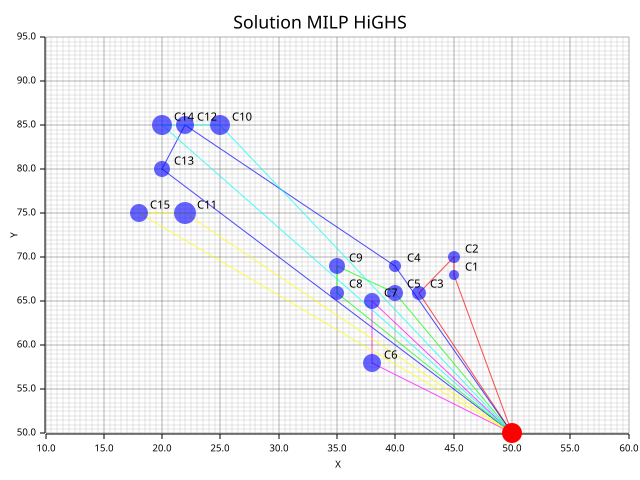

In [14]:
{
    // Carte de la tournee MILP : sectors propres, aucun croisement.
    use highs::{RowProblem, Sense, HighsModelStatus};

    // Instance identique au jumeau Python : noeud 0 = depot, 1..15 = clients.
    let points: Vec<(f64, f64)> = vec![
        (50.0, 50.0),                                             // 0 : depot
        (45.0, 68.0), (45.0, 70.0), (42.0, 66.0), (40.0, 69.0), (40.0, 66.0),
        (38.0, 58.0), (38.0, 65.0), (35.0, 66.0), (35.0, 69.0), (25.0, 85.0),
        (22.0, 75.0), (22.0, 85.0), (20.0, 80.0), (20.0, 85.0), (18.0, 75.0),
    ];
    let demands: Vec<i64> = vec![0, 10, 15, 18, 15, 20, 25, 20, 18, 22, 30, 35, 25, 20, 30, 25];
    let capacity: i64 = 60;
    let nveh: usize = 6;
    let n = points.len();
    let dist = |i: usize, j: usize| {
        let (dx, dy) = (points[i].0 - points[j].0, points[i].1 - points[j].1);
        (dx * dx + dy * dy).sqrt()
    };

    // ---- Formulation MILP flot (Gavish-Graves) ----
    // x[i][j] = 1 si un vehicule emprunte l'arc i->j (binaire)
    // f[i][j] = charge transportee sur l'arc i->j (continue, bornee par la capacite)
    // Objectif : minimiser la somme des distances des arcs empruntes.
    let arcs: Vec<(usize, usize)> = (0..n)
        .flat_map(|i| (0..n).filter(move |&j| j != i).map(move |j| (i, j)))
        .collect();
    let aidx = |i: usize, j: usize| arcs.iter().position(|&(a, b)| a == i && b == j).unwrap();

    let mut pb = RowProblem::new();
    let x: Vec<highs::Col> = arcs.iter().map(|&(i, j)| pb.add_integer_column(dist(i, j), 0..=1)).collect();
    let f: Vec<highs::Col> = arcs.iter().map(|_| pb.add_column(0.0, 0.0..=capacity as f64)).collect();

    // (1) degre : chaque client a exactement un arc entrant et un arc sortant
    for j in 1..n {
        pb.add_row(1.0..=1.0, (0..n).filter(|&i| i != j).map(|i| (x[aidx(i, j)], 1.0)));
        pb.add_row(1.0..=1.0, (0..n).filter(|&i| i != j).map(|i| (x[aidx(j, i)], 1.0)));
    }
    // (2) au plus nveh tournees (arcs sortant du depot, arcs y revenant)
    pb.add_row(0.0..=nveh as f64, (1..n).map(|j| (x[aidx(0, j)], 1.0)));
    pb.add_row(0.0..=nveh as f64, (1..n).map(|j| (x[aidx(j, 0)], 1.0)));
    // (3) conservation du flot par client : charge_entree - charge_sortie = demande
    for j in 1..n {
        let dj = demands[j] as f64;
        let mut terms: Vec<(highs::Col, f64)> = Vec::new();
        for i in 0..n {
            if i != j {
                terms.push((f[aidx(i, j)], 1.0));
                terms.push((f[aidx(j, i)], -1.0));
            }
        }
        pb.add_row(dj..=dj, terms);
    }
    // (4) couplage flot/arc : d_j * x_ij <= f_ij <= Q * x_ij
    // (les bornes portent le produit : f - Q*x <= 0 et f - d_j*x >= 0,
    //  jamais f - Q*x <= Q qui laisserait du flot fantome sur les arcs inutilises)
    for (k, &(i, j)) in arcs.iter().enumerate() {
        pb.add_row(..=0.0, &[(f[k], 1.0), (x[k], -(capacity as f64))]);
        if j >= 1 {
            let dj = demands[j] as f64;
            pb.add_row(0.., &[(f[k], 1.0), (x[k], -dj)]);
        }
    }

    // Resolution : le statut est matche et affiche, jamais avale.
    let solved = pb.optimise(Sense::Minimise).solve();
    println!("statut: {:?}", solved.status());
    assert_eq!(solved.status(), HighsModelStatus::Optimal, "le MILP doit etre optimal");
    let sol = solved.get_solution();
    let on = |i: usize, j: usize| sol[x[aidx(i, j)]] > 0.5;

    // Extraction des tournees : partir du depot, suivre les arcs selectionnes.
    let mut routes: Vec<Vec<usize>> = Vec::new();
    for first in 1..n {
        if on(0, first) {
            let mut route: Vec<usize> = Vec::new();
            let mut cur = first;
            loop {
                route.push(cur - 1);
                let nxt = (0..n)
                    .find(|&j| j != cur && on(cur, j))
                    .expect("degre sortant = 1 garanti par la contrainte (1)");
                if nxt == 0 {
                    break;
                }
                cur = nxt;
            }
            routes.push(route);
        }
    }

    // Validite structurelle, verifiee independamment du solveur.
    let mut count = vec![0usize; n - 1];
    for r in &routes {
        for &c in r {
            count[c] += 1;
        }
    }
    let capacite_ok = routes
        .iter()
        .all(|r| r.iter().map(|&c| demands[c + 1]).sum::<i64>() <= capacity);
    let valide = count.iter().all(|&c| c == 1) && capacite_ok;

    // Distance totale : meme accumulation, meme ordre que le glouton.
    let mut dist_tot = 0.0f64;
    for r in &routes {
        let mut prev = 0usize;
        for &c in r {
            dist_tot += dist(prev, c + 1);
            prev = c + 1;
        }
        dist_tot += dist(prev, 0);
    }
    let title = format!("Solution MILP HiGHS - Distance: {:.2}, {} tournees", dist_tot, routes.len());
    use plotters::prelude::*;

    // SVG emis en image/svg+xml (pas de <div> HTML) : un SVG enrobe dans du
    // HTML ne s'affiche pas dans le rendu GitHub du carnet (#26613).
    let mut svg = String::new();
    {
        let root = SVGBackend::with_string(&mut svg, (640, 480)).into_drawing_area();
        root.fill(&WHITE)?;
        let mut chart = ChartBuilder::on(&root)
            .caption("Solution MILP HiGHS", ("sans-serif", 22))
            .margin(10)
            .x_label_area_size(36)
            .y_label_area_size(36)
            .build_cartesian_2d(10f64..60f64, 50f64..95f64)?;
        chart.configure_mesh().x_desc("X").y_desc("Y").draw()?;
        // tournees : une polyline (et une couleur) par vehicule
        let colors = [&RED, &BLUE, &GREEN, &MAGENTA, &CYAN, &YELLOW];
        for (k, route) in routes.iter().enumerate() {
            let mut path: Vec<(f64, f64)> = vec![points[0]];
            for &c in route {
                path.push(points[c + 1]);
            }
            path.push(points[0]);
            chart.draw_series(LineSeries::new(path.iter().copied(), colors[k % colors.len()].mix(0.7)))?;
        }
        // depot : gros cercle rouge
        chart.draw_series(std::iter::once(Circle::new(points[0], 10, RED.filled())))?;
        // clients : taille proportionnelle a la demande + etiquette
        chart.draw_series(points[1..].iter().enumerate().map(|(i, &(x, y))| {
            Circle::new((x, y), 3 + (demands[i + 1] as u32) / 4, BLUE.mix(0.6).filled())
        }))?;
        for (i, &(x, y)) in points[1..].iter().enumerate() {
            chart.draw_series(std::iter::once(Text::new(
                format!("C{}", i + 1), (x + 1.0, y + 1.5), ("sans-serif", 14).into_font())))?;
        }
    }
    println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", svg);
}

### Lecture : la carte du solveur, confrontée à celle du glouton

La visualisation réutilise le même tracé — même figuré, mêmes couleurs, une seule chose change : la solution
tracée. La comparaison visuelle avec la section 5 se lit en deux gestes. Les tournées du solveur dessinent des
**secteurs** partant du dépôt, quand celles du glouton s'enroulaient en spirales dictées par l'ordre
d'insertion ; et les croisements qui subsistaient sur la carte glouton ont disparu, y compris **entre**
tournées — ce que le 2-opt, cantonné à l'ordre interne, ne pouvait pas toucher.

C'est le pendant géométrique du gain mesuré juste avant : l'œil voit la cause (frontières de secteurs
propres, aucun zigzag inter-bandes), la métrique en donne le prix. Les deux lectures ensemble disent pourquoi
un moteur exact reste supérieur à une chaîne glouton + 2-opt : il retouche l'affectation **et** l'ordre,
simultanément, sous la même contrainte de capacité.

## 8. Exercices

### Exercice 1 : Algorithme du Plus Proche Voisin

Implémentez un algorithme qui construit les tournées en sélectionnant toujours le client le plus proche du
dernier client visité, tout en respectant les contraintes de capacité.

In [15]:
{
    // Exercice 1 : a completer.
    // Construire les tournees avec l'algorithme du plus proche voisin :
    // partir du depot, choisir toujours le client non desservi le plus proche
    // du dernier client visite, en respectant la capacite.
    fn nearest_neighbor(
        _points: &[(f64, f64)],
        _demands: &[i64],
        _capacity: i64,
        _num_vehicles: usize,
    ) -> Option<Vec<Vec<usize>>> {
        None // Exercice a completer : retourner les tournees construites
    }
    println!("Exercice a completer : nearest_neighbor");
}

Exercice a completer : nearest_neighbor


()

### Exercice 2 : Métaheuristique - Recuit Simulé

Implémentez un algorithme de recuit simulé pour explorer l'espace de solutions et échapper aux optima locaux.

In [16]:
{
    // Exercice 2 : a completer.
    // Recuit simulé : accepter de temps en temps un mouvement dégradant pour
    // échapper des optima locaux, en refroidissant progressivement.
    fn simulated_annealing(
        _routes: &[Vec<usize>],
        _distances: &[Vec<f64>],
        _initial_temp: f64,
        _cooling_rate: f64,
    ) -> Option<Vec<Vec<usize>>> {
        None // Exercice a completer : retourner la solution amelioree
    }
    println!("Exercice a completer : simulated_annealing");
}

Exercice a completer : simulated_annealing


()

### Exercice 3 : VRP avec Fenêtres de Temps (VRPTW)

Étendez le modèle pour inclure des contraintes de fenêtres de temps pour chaque client (temps minimum et
maximum de livraison). Dans le MILP, chaque client `j` gagnerait une fenêtre `[e_j, l_j]` et la variable de
flot deviendrait un temps d'arrivée.

In [17]:
{
    // Exercice 3 : a completer.
    // VRPTW : chaque client gagne une fenetre de temps [earliest, latest] ;
    // valider qu'une solution est realisable temporellement.
    fn validate_time_windows(
        _routes: &[Vec<usize>],
        _time_windows: &[(i64, i64)],
        _service_times: &[i64],
    ) -> bool {
        false // Exercice a completer : retourner la validite temporelle
    }
    println!("Exercice a completer : validate_time_windows");
}

Exercice a completer : validate_time_windows


()

## 9. Résumé

Dans ce carnet, nous avons exploré :

1. **Modélisation VRP** : Représentation formelle du problème (instance, solution, validité)
2. **Algorithme glouton** : Construction de solution par insertion
3. **Recherche locale** : Amélioration avec 2-opt
4. **Solveur exact** : Formulation MILP flot résolue par HiGHS (crate `highs`)
5. **Comparaison honnête** : le glouton et le 2-opt sur la même instance, dominés par l'optimum MILP

### Perspectives

- **Métaheuristiques avancées** : Algorithmes génétiques, colonie de fourmis
- **Problèmes dynamiques** : VRP avec demandes dynamiques
- **VRPTW** : fenêtres de temps (exercice 3)
- **Applications réelles** : Logistique, transport de marchandises, livraison

### Références

- Toth, P., & Vigo, D. (2014). *The Vehicle Routing Problem*
- Cordeau, J. F., et al. (2002). *A guide to vehicle routing heuristics*
- Gavish, B., & Graves, S. (1978). *The travelling salesman problem and related problems* (formulation flot)
- Russell, S., & Norvig, P. (2020). *Artificial Intelligence: A Modern Approach* - Chapitre 10

**Jumeau** : [App-17 VRP Python](App-17-VRP-Logistics-Python.ipynb) (OR-Tools Routing)